# 01 — Area studi (AOI)

- **Input**: poligon kampus UI dari OSM (`raw/aoi_ui.gpkg`, hasil `osmnx.geocode_to_gdf`); bila belum ada,
  geocode ulang dengan fallback bbox manual.
- **Proses**: proyeksi ke EPSG:32748, buffer 50 m, dan buffer 3 km untuk evaluasi terrain.
- **Output**: `interim/aoi.gpkg` (layer `aoi`, `aoi_buf50`, `aoi_terrain`), luas AOI, peta lokasi (setara Fig. 1–2).

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
from shapely.geometry import box

from ui3d_common import CFG, CRS, hillshade, interim, raw, savefig

In [2]:
if raw("aoi").exists():
    aoi_ll = gpd.read_file(raw("aoi"), layer="aoi")
else:
    import osmnx as ox
    try:
        aoi_ll = ox.geocode_to_gdf(CFG["aoi"]["query"])[["geometry"]]
    except Exception as e:  # noqa: BLE001 - fallback sesuai PRD
        print("geocode gagal, pakai bbox manual:", e)
        aoi_ll = gpd.GeoDataFrame(geometry=[box(*CFG["aoi"]["bbox_fallback"])], crs=4326)

aoi = aoi_ll[["geometry"]].to_crs(CRS)
aoi["name"] = "Universitas Indonesia"
aoi_buf = gpd.GeoDataFrame({"name": ["AOI + 50 m"]}, geometry=aoi.buffer(CFG["aoi"]["buffer_m"]), crs=CRS)
aoi_terrain = gpd.GeoDataFrame({"name": ["AOI + 3 km"]}, geometry=aoi.buffer(CFG["aoi"]["terrain_buffer_m"]), crs=CRS)

dst = interim("aoi.gpkg")
aoi.to_file(dst, layer="aoi")
aoi_buf.to_file(dst, layer="aoi_buf50")
aoi_terrain.to_file(dst, layer="aoi_terrain")

area = aoi.area.iloc[0]
print(f"Luas AOI: {area / 1e4:,.1f} ha = {area / 1e6:.2f} km²")
print(f"Luas AOI + 50 m: {aoi_buf.area.iloc[0] / 1e6:.2f} km²; AOI + 3 km: {aoi_terrain.area.iloc[0] / 1e6:.2f} km²")

Luas AOI: 276.6 ha = 2.77 km²
Luas AOI + 50 m: 3.21 km²; AOI + 3 km: 54.82 km²


## Peta lokasi (setara Fig. 1–2)

Kiri: AOI dalam konteks buffer terrain 3 km di atas DEMNAS (warna elevasi di atas hillshade, z×3; rumus hillshade\ndi notebook 02). Kanan: AOI di atas citra Esri.

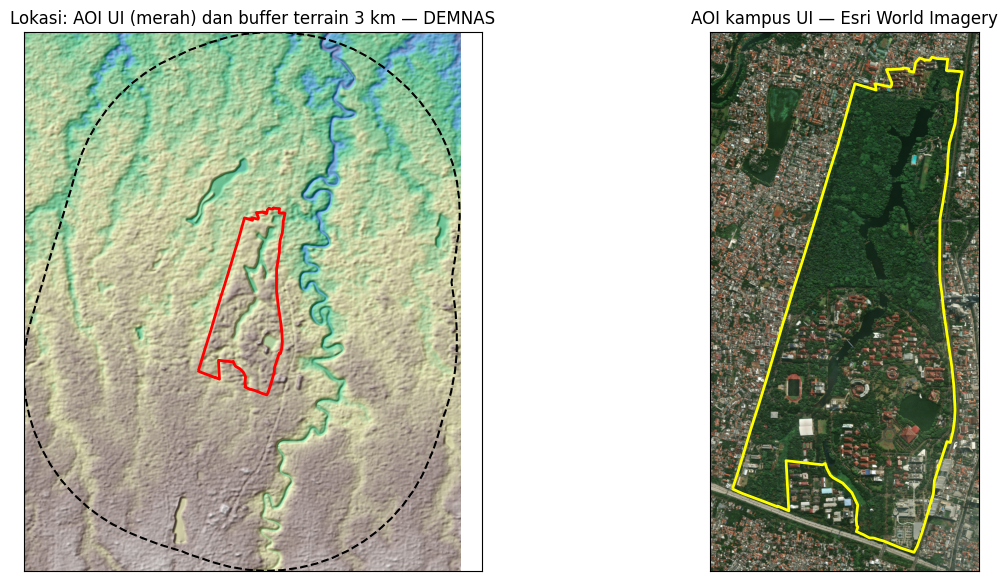

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

with rasterio.open(raw("demnas")) as src:
    b = aoi_terrain.to_crs(src.crs).total_bounds
    win = rasterio.windows.from_bounds(*b, src.transform)
    dem = src.read(1, window=win).astype(float)
    wtr = src.window_transform(win)
    # DEMNAS dalam derajat: ukuran piksel ke meter (~111,3 km/derajat di ekuator) untuk hillshade
    hs = hillshade(dem, src.res[0] * 111_320, z_factor=3)
    show(hs, transform=wtr, ax=ax[0], cmap="gray", vmin=0, vmax=1)
    show(dem, transform=wtr, ax=ax[0], cmap="terrain", alpha=0.45)
aoi_terrain.to_crs(4326).boundary.plot(ax=ax[0], color="k", ls="--")
aoi.to_crs(4326).boundary.plot(ax=ax[0], color="red", lw=2)
ax[0].set_title("Lokasi: AOI UI (merah) dan buffer terrain 3 km — DEMNAS")

with rasterio.open(raw("imagery")) as src:
    f = max(1, src.width // 1500)
    img = src.read(out_shape=(3, src.height // f, src.width // f))
    tr = src.transform * src.transform.scale(src.width / img.shape[2], src.height / img.shape[1])
    show(img, transform=tr, ax=ax[1])
    aoi.to_crs(src.crs).boundary.plot(ax=ax[1], color="yellow", lw=2)
ax[1].set_title("AOI kampus UI — Esri World Imagery")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
savefig(fig, "fig01_02_lokasi_aoi.png")
plt.show()